# 실습 2. 딥러닝 기초: Data · Model · Loss · Optimizer
**통계청 AI 교육 · 2026.10.27(화) 4~6교시**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sunghoonim/stat-ai-2026/blob/main/lab2_deep_learning_basics.ipynb)

### 오늘의 목표
- 딥러닝 학습의 4요소(Data · Model · Loss · Optimizer)를 **코드에서 직접 찾아본다**
- 설정값을 바꿔 가며 **학습률 · 모델 크기 · 최적화 방법**이 결과를 어떻게 바꾸는지 눈으로 확인한다
- 인구센서스 자료로 **로지스틱 회귀와 신경망을 비교**한다
- **사전학습 언어모델**로 사업체 설명을 산업분류에 배정해 본다

| 단계 | 내용 | 시간 |
|---|---|---|
| 1단계 | 돌려보기 | 5분 |
| 2단계 | 설정값 바꿔보기 | 15분 |
| 3단계 | 통계 데이터로 비교 (로지스틱 회귀 vs 신경망) | 10분 |
| 4단계 | 사전학습 모델 써보기 (산업분류) | 10분 |

**합계 40분** · 5–6교시에 모두 함께 합니다. 끝나면 실습 3으로 이어서 합니다(25분).

### 사용법
1. 메뉴 **런타임 → 런타임 유형 변경 → CPU** (GPU는 필요 없습니다)
2. 메뉴 **런타임 → 모두 실행**, 또는 셀을 하나씩 선택하고 `Shift + Enter`
3. 이 노트북에는 **실행 결과가 미리 저장되어 있습니다.** 실행이 막혀도 결과를 보며 따라오세요. 다시 실행하면 숫자가 조금 다를 수 있습니다(난수·버전 차이).

### 코드 속 4요소 표시
| 표시 | 요소 | 통계로 말하면 |
|---|---|---|
| 🟦 **Data** | 데이터 | 표본 $(X, y)$ |
| 🟩 **Model** | 모델 | 회귀식 (가중치 = 계수) |
| 🟧 **Loss** | 손실함수 | 최소제곱 / 음의 로그우도 |
| 🟥 **Optimizer** | 최적화 | 계수를 찾는 수치최적화 방법 |

## 0. 준비
필요한 도구를 불러옵니다. 난수 시드를 고정해서 누가 실행해도 같은 결과가 나오게 합니다.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import sklearn
from sklearn.model_selection import train_test_split

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cpu"   # 이 실습은 CPU만으로 충분합니다
t_start = time.time()

print("PyTorch", torch.__version__, "| scikit-learn", sklearn.__version__, "| device:", device)

PyTorch 2.14.1 | scikit-learn 1.9.1 | device: cpu


In [2]:
#@title 🎨 그림 도우미 함수 (실행만 하세요. 내용은 몰라도 됩니다)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

def plot_boundary(ax, model, X, y, title=""):
    """모델이 학습한 경계선과 데이터를 그린다."""
    X = np.asarray(X); y = np.asarray(y)
    x0, x1 = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y0, y1 = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x0, x1, 200), np.linspace(y0, y1, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        p = torch.sigmoid(model(grid)).numpy().reshape(xx.shape)
    ax.contourf(xx, yy, p, levels=np.linspace(0, 1, 11), cmap="coolwarm", alpha=0.35)
    ax.contour(xx, yy, p, levels=[0.5], colors="k", linewidths=1.2)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])

def plot_loss(ax, hist, title="Loss", log=True):
    """epoch별 train / val loss 곡선을 그린다."""
    ax.plot(hist["train"], label="train loss")
    if hist.get("val"):
        ax.plot(hist["val"], "--", label="val loss")
    if log:
        ax.set_yscale("log")
    ax.set_xlabel("epoch"); ax.set_title(title, fontsize=10); ax.legend(fontsize=8)

def show(results, suptitle=""):
    """여러 실험 결과를 나란히: 위는 경계선, 아래는 loss 곡선 (y축 공유)."""
    n = len(results)
    fig, axes = plt.subplots(2, n, figsize=(3.6 * n, 6.6), squeeze=False)
    for j, r in enumerate(results):
        d = r["data"]
        plot_boundary(axes[0, j], r["model"], d["Xtr"], d["ytr"],
                      r["label"] + f"\ntrain acc {r['acc_train']:.0%} | val acc {r['acc_val']:.0%}")
        plot_loss(axes[1, j], r["hist"], title="loss (log scale)")
    vals = np.concatenate([np.r_[r["hist"]["train"], r["hist"]["val"]] for r in results])
    vals = vals[np.isfinite(vals) & (vals > 0)]
    for ax in axes[1]:
        ax.set_ylim(vals.min() * 0.8, vals.max() * 1.25)
    if suptitle:
        fig.suptitle(suptitle, fontsize=12)
    fig.tight_layout(); plt.show()

---
## 1단계. 돌려보기 (5분)
**문제:** 점 400개가 두 집단(빨강/파랑)으로 나뉘어 있습니다. 두 집단을 가르는 경계를 찾아야 합니다.

로지스틱 회귀는 **직선** 경계만 그을 수 있습니다. 이 데이터처럼 초승달이 맞물린 모양이면 직선으로는 잘 안 갈립니다.
신경망은 어떤 경계를 찾을까요?

### 1-1. 🟦 데이터 보기

X 모양: (400, 2)   → 400명 × 설명변수 2개 (x1, x2)
y 앞 10개: [0. 1. 1. 0. 1. 0. 0. 1. 0. 1.]   → 0 또는 1


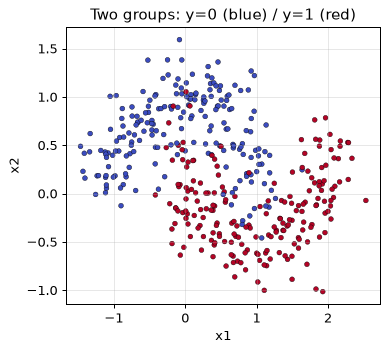

In [3]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=400, noise=0.25, random_state=SEED)
X = X.astype("float32"); y = y.astype("float32")
print("X 모양:", X.shape, "  → 400명 × 설명변수 2개 (x1, x2)")
print("y 앞 10개:", y[:10], "  → 0 또는 1")

plt.figure(figsize=(4.5, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=15, edgecolor="k", linewidth=0.3)
plt.title("Two groups: y=0 (blue) / y=1 (red)"); plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

### 1-2. 학습 코드: 4요소가 전부 들어 있습니다
아래 셀이 **딥러닝 학습의 전부**입니다. 색 표시를 따라 4요소를 찾아보세요.

- 🟩 **Model:** 입력 2개 → 은닉 뉴런 16개 → 16개 → 출력 1개. 출력에 시그모이드를 씌우면 '빨강일 확률'이 됩니다.
- 🟧 **Loss:** `BCEWithLogitsLoss` = 이진 교차엔트로피 = **로지스틱 회귀의 음의 로그우도**와 같은 식입니다.
- 🟥 **Optimizer:** `Adam`. 기울기 반대 방향으로 가중치를 조금씩 움직입니다. 한 걸음의 크기가 학습률 `lr`입니다.
- `loss.backward()`가 **역전파**입니다. 연쇄법칙으로 모든 가중치의 기울기를 자동으로 계산합니다.

In [4]:
# 🟦 Data: 표본을 텐서(숫자 묶음)로 바꾸기
X_t, y_t = torch.tensor(X), torch.tensor(y)

# 🟩 Model: 2 → 16 → 16 → 1
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 16), nn.ReLU(),
    nn.Linear(16, 1),
)
# 🟧 Loss: 이진 교차엔트로피 (= 로지스틱 회귀의 음의 로그우도)
loss_fn = nn.BCEWithLogitsLoss()
# 🟥 Optimizer: Adam, 학습률 0.05
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)

losses = []
for epoch in range(200):
    optimizer.zero_grad()                         # 지난번 기울기 지우기
    loss = loss_fn(model(X_t).squeeze(1), y_t)    # 🟧 예측하고 손실 계산
    loss.backward()                               # 기울기 계산 (역전파)
    optimizer.step()                              # 🟥 기울기 반대 방향으로 한 걸음
    losses.append(loss.item())
    if epoch % 25 == 0 or epoch == 199:
        print(f"epoch {epoch:3d} | loss {loss.item():.4f}")

epoch   0 | loss 0.6985
epoch  25 | loss 0.2289
epoch  50 | loss 0.1603
epoch  75 | loss 0.1547
epoch 100 | loss 0.1539
epoch 125 | loss 0.1541
epoch 150 | loss 0.1530
epoch 175 | loss 0.1538
epoch 199 | loss 0.1510


### 1-3. 결과 보기

정확도: 92.5%


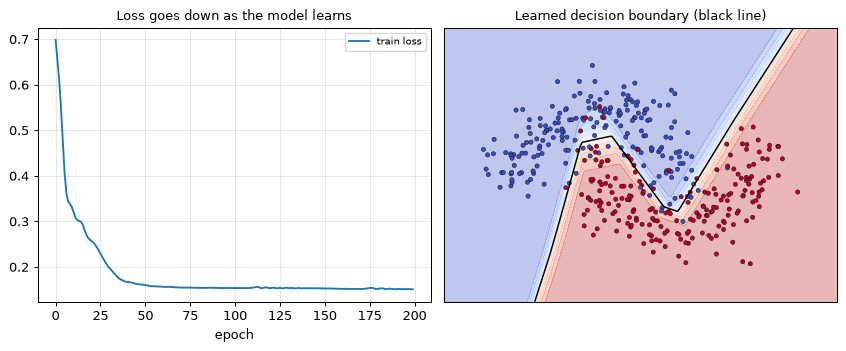

In [5]:
with torch.no_grad():
    acc = ((model(X_t).squeeze(1) > 0).float() == y_t).float().mean().item()
print(f"정확도: {acc:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
plot_loss(axes[0], {"train": losses}, title="Loss goes down as the model learns", log=False)
plot_boundary(axes[1], model, X, y, title="Learned decision boundary (black line)")
plt.tight_layout(); plt.show()

> ✅ **확인할 것**
> - loss가 epoch마다 줄어드나요? → 🟥 Optimizer가 🟧 Loss를 줄이는 방향으로 🟩 Model의 가중치를 고치고 있다는 뜻입니다.
> - 경계선이 **곡선**인가요? → 은닉층 + ReLU(비선형) 덕분입니다. 은닉층을 빼면 어떻게 될지는 2단계에서 확인합니다.

---
## 2단계. 설정값 바꿔보기 (15분)
이제 코드는 건드리지 않고 **숫자만 바꿔서** 결과를 비교합니다. 아래 `train(...)` 함수 안에는 1단계와 똑같은 학습 루프가 들어 있습니다.

| 바꿀 설정 | 4요소 | 의미 |
|---|---|---|
| `hidden` | 🟩 Model | 은닉 뉴런 수 (0이면 은닉층 없음) |
| `lr` | 🟥 Optimizer | 학습률, 한 걸음의 크기 |
| `optimizer` | 🟥 Optimizer | `"sgd"`, `"momentum"`, `"adam"` |
| `weight_decay` | 🟧 Loss | 가중치 크기에 주는 벌점 (Ridge의 λ) |
| `epochs` | - | 반복 횟수 |

이번에는 데이터를 **학습용(train)과 검증용**(val)으로 나눕니다. 모델은 train만 보고 배우고, val은 '처음 보는 데이터에서도 잘 맞히는지' 확인하는 데만 씁니다.

In [6]:
#@title 🔧 실습 도우미 함수 (실행만 하세요)
def make_split(X, y, test_size, seed=SEED):
    """train / val로 나누고 텐서로 바꾼다."""
    Xtr, Xva, ytr, yva = train_test_split(X.astype("float32"), y.astype("float32"),
                                          test_size=test_size, random_state=seed, stratify=y)
    return dict(Xtr=torch.tensor(Xtr), ytr=torch.tensor(ytr), Xva=torch.tensor(Xva), yva=torch.tensor(yva))

def build_model(hidden, n_in=2, layers=2):
    if hidden == 0:                      # 은닉층 없음 = 로지스틱 회귀
        return nn.Linear(n_in, 1)
    mods, d = [], n_in
    for _ in range(layers):
        mods += [nn.Linear(d, hidden), nn.ReLU()]
        d = hidden
    return nn.Sequential(*mods, nn.Linear(d, 1))

def make_optimizer(name, params, lr, weight_decay=0.0):
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, weight_decay=weight_decay)
    if name == "momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    raise ValueError('optimizer는 "sgd", "momentum", "adam" 중 하나')

def train(data, hidden=16, lr=0.05, optimizer="adam", epochs=500, weight_decay=0.0, seed=SEED):
    torch.manual_seed(seed)
    model = build_model(hidden)                                            # 🟩 Model
    loss_fn = nn.BCEWithLogitsLoss()                                       # 🟧 Loss
    opt = make_optimizer(optimizer, model.parameters(), lr, weight_decay)  # 🟥 Optimizer
    hist = {"train": [], "val": []}
    for epoch in range(epochs):
        opt.zero_grad()
        loss = loss_fn(model(data["Xtr"]).squeeze(1), data["ytr"])        # 🟦 Data → 🟧 Loss
        loss.backward()
        opt.step()
        with torch.no_grad():
            hist["train"].append(loss.item())
            hist["val"].append(loss_fn(model(data["Xva"]).squeeze(1), data["yva"]).item())
    with torch.no_grad():
        acc = lambda X, y: ((model(X).squeeze(1) > 0).float() == y).float().mean().item()
        acc_train, acc_val = acc(data["Xtr"], data["ytr"]), acc(data["Xva"], data["yva"])
    label = f"hidden={hidden}, {optimizer}, lr={lr}" + (f", wd={weight_decay}" if weight_decay else "")
    print(f"{label:38s} | loss train {hist['train'][-1]:.3f} / val {hist['val'][-1]:.3f}"
          f" | acc train {acc_train:.1%} / val {acc_val:.1%}")
    return dict(model=model, hist=hist, label=label, data=data, acc_train=acc_train, acc_val=acc_val)

# 1단계 데이터를 train 75% / val 25%로 나누기
moons = make_split(X, y, test_size=0.25)
print("moons: train", len(moons["ytr"]), "/ val", len(moons["yva"]))

moons: train 300 / val 100


### 2-0. 은닉층 없는 신경망 = 로지스틱 회귀
은닉층을 빼면(`hidden=0`) 모델은 $\sigma(w_1 x_1 + w_2 x_2 + b)$, 정확히 **로지스틱 회귀**입니다.
손실함수(이진 교차엔트로피)도 로지스틱 회귀의 음의 로그우도와 같은 식입니다.
그러면 신경망 방식(경사하강)으로 찾은 가중치가 통계 패키지(`statsmodels`)의 최대우도 추정치와 같아야겠죠?

In [7]:
import statsmodels.api as sm

res0 = train(moons, hidden=0, lr=0.1, optimizer="adam", epochs=3000)
lin = res0["model"]

Xtr_np, ytr_np = moons["Xtr"].numpy().astype(float), moons["ytr"].numpy()
logit = sm.Logit(ytr_np, sm.add_constant(Xtr_np)).fit(disp=0)

compare = pd.DataFrame({
    "신경망 (PyTorch, 경사하강)": [lin.bias.item(), *lin.weight.detach().numpy().ravel()],
    "로지스틱 회귀 (statsmodels, MLE)": logit.params,
}, index=["절편 b", "x1 계수 w1", "x2 계수 w2"]).round(4)
print(f"신경망 최종 loss        = {res0['hist']['train'][-1]:.5f}")
print(f"-(로그우도) / 표본 수   = {-logit.llf / len(ytr_np):.5f}   ← 같은 값!")
compare

hidden=0, adam, lr=0.1                 | loss train 0.342 / val 0.249 | acc train 85.0% / val 93.0%
신경망 최종 loss        = 0.34243
-(로그우도) / 표본 수   = 0.34243   ← 같은 값!


,"신경망 (PyTorch, 경사하강)","로지스틱 회귀 (statsmodels, MLE)"
절편 b,0.3893,0.3893
x1 계수 w1,1.2250,1.2250
x2 계수 w2,-3.6617,-3.6617


같은 답이 나옵니다. **딥러닝의 Loss와 Optimizer는 통계의 '우도'와 '추정 알고리즘'을 일반화한 것**입니다.
다만 통계 패키지는 아래처럼 **표준오차와 p값**까지 주지만, 신경망은 보통 예측만 합니다. 이 차이는 3단계에서 다시 이야기합니다.

In [8]:
logit.summary2().tables[1].set_axis(["const", "x1", "x2"]).round(3)

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,0.389,0.233,1.670,0.095,-0.068,0.846
x1,1.225,0.206,5.957,0.000,0.822,1.628
x2,-3.662,0.473,-7.743,0.000,-4.589,-2.735


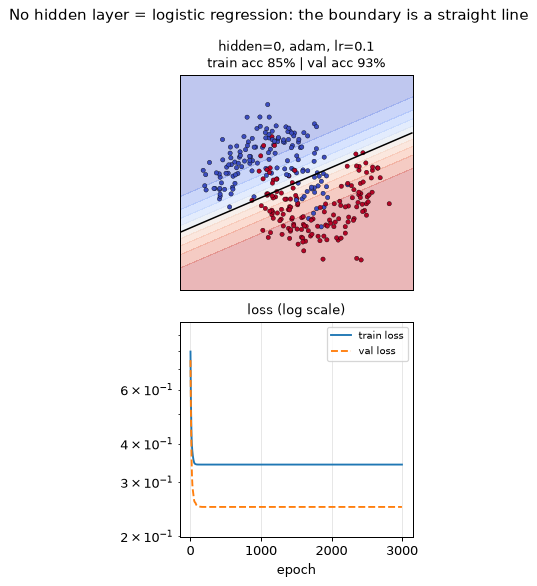

In [9]:
show([res0], "No hidden layer = logistic regression: the boundary is a straight line")

### 2-1. 🟥 학습률(lr): 한 걸음의 크기
같은 모델(hidden=16)을 **SGD**로 학습하면서 학습률만 바꿉니다.
(여기서는 데이터가 작아서 매번 전체 데이터로 기울기를 계산합니다.)

hidden=16, sgd, lr=0.01                | loss train 0.575 / val 0.553 | acc train 81.7% / val 85.0%
hidden=16, sgd, lr=1                   | loss train 0.155 / val 0.155 | acc train 93.3% / val 91.0%
hidden=16, sgd, lr=20                  | loss train 1.492 / val 2.304 | acc train 65.7% / val 63.0%


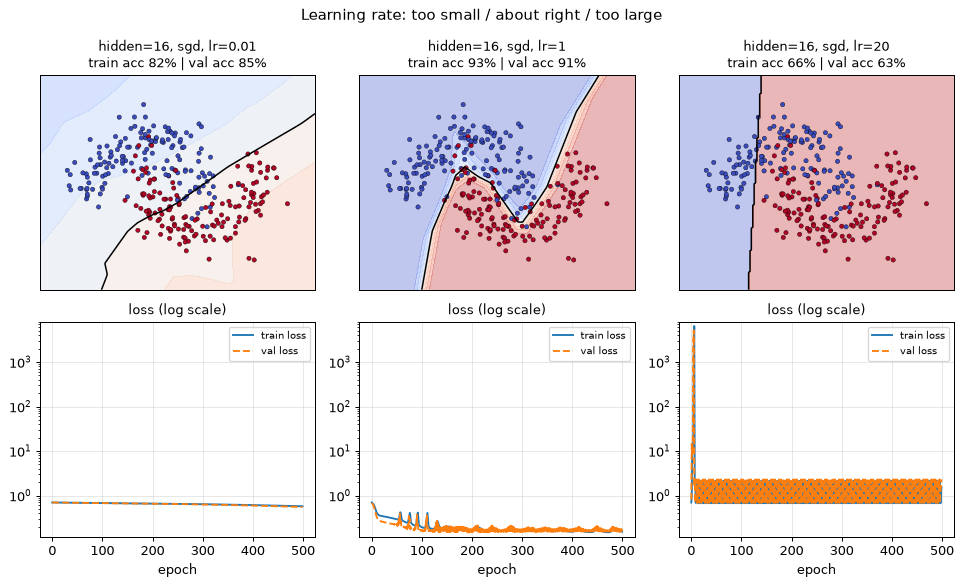

In [10]:
r_lr = [train(moons, hidden=16, optimizer="sgd", lr=lr, epochs=500) for lr in [0.01, 1, 20]]
show(r_lr, "Learning rate: too small / about right / too large")

> ✅ **확인할 것**
> - `lr=0.01`: 너무 조심스러워서 500번을 걸어도 아직 내려가는 중입니다. 경계도 덜 휘었습니다.
> - `lr=1`: 빠르게 내려가서 안정됩니다.
> - `lr=20`: 보폭이 너무 커서 골짜기를 넘어 다닙니다. loss가 **튀어 오르고(발산)** 정확도가 떨어집니다.
>
> 실무에서 가장 먼저 조정하는 값이 학습률입니다.

### 2-2. 🟩 모델 크기와 과적합: 그리고 🟧 Ridge 벌점
이번에는 **표본이 작고(학습용 160개) 잡음이 큰** 데이터를 씁니다. 은닉 뉴런 수를 2 → 16 → 512로 키워 봅니다.
마지막 칸은 512개 그대로에 `weight_decay`(가중치 벌점)를 줍니다.

hidden=2, adam, lr=0.01                | loss train 0.360 / val 0.360 | acc train 85.0% / val 86.9%
hidden=16, adam, lr=0.01               | loss train 0.246 / val 0.276 | acc train 88.1% / val 88.1%
hidden=512, adam, lr=0.01              | loss train 0.000 / val 1.921 | acc train 100.0% / val 88.1%
hidden=512, adam, lr=0.01, wd=0.01     | loss train 0.286 / val 0.261 | acc train 85.6% / val 90.0%


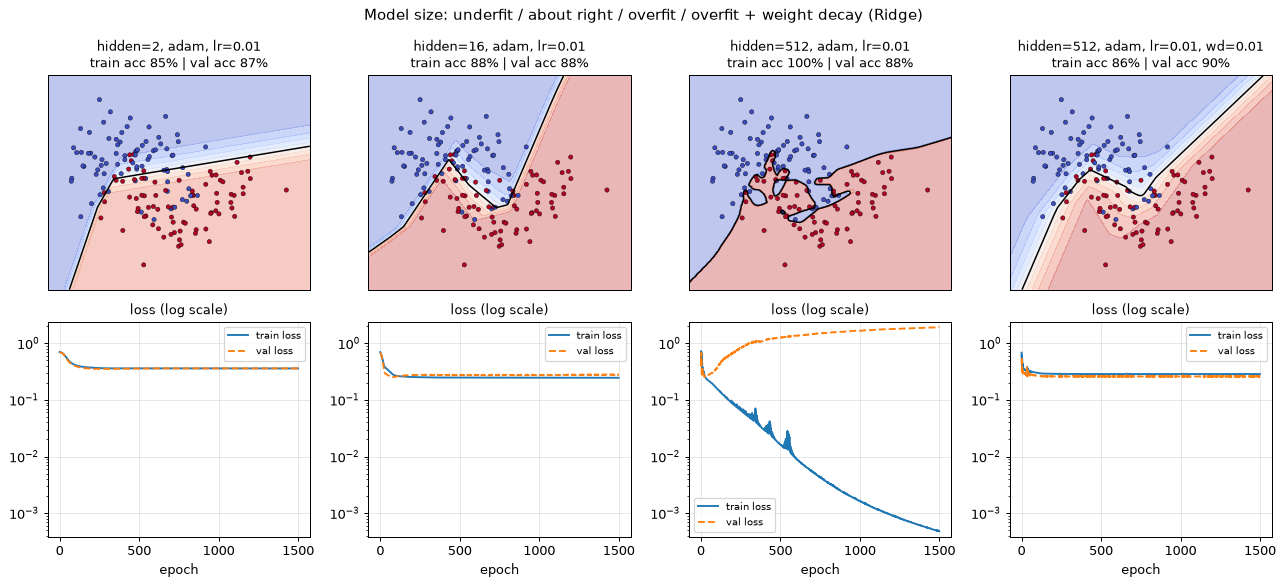

In [11]:
X2, y2 = make_moons(n_samples=320, noise=0.35, random_state=1)
moons_small = make_split(X2, y2, test_size=0.5)

r_size = [train(moons_small, hidden=h, lr=0.01, optimizer="adam", epochs=1500) for h in [2, 16, 512]]
r_size.append(train(moons_small, hidden=512, lr=0.01, optimizer="adam", epochs=1500, weight_decay=0.01))
show(r_size, "Model size: underfit / about right / overfit / overfit + weight decay (Ridge)")

> ✅ **확인할 것**
> - `hidden=512`: train loss는 거의 0(train 정확도 100%)인데, **val loss는 epoch이 갈수록 올라갑니다.** 표본의 잡음까지 외운 **과적합**입니다. 경계선이 점 하나하나를 피해 구불구불합니다.
> - `weight_decay=0.01`: 손실에 $\lambda \lVert w \rVert^2$ 벌점을 더합니다. **Ridge 회귀와 같은 아이디어**입니다. 같은 512개 모델인데 경계가 부드러워지고 val loss가 안정됩니다.
> - 통계에서 말하는 **편향-분산 trade-off**, **검증용 표본**(교차검증)이 딥러닝에서도 그대로 핵심입니다.

### 2-3. 🟥 최적화 방법: SGD vs Momentum vs Adam
같은 모델, 같은 학습률(0.05)에서 방법만 바꿉니다.

hidden=16, sgd, lr=0.05                | loss train 0.336 / val 0.251 | acc train 86.3% / val 93.0%
hidden=16, momentum, lr=0.05           | loss train 0.160 / val 0.160 | acc train 93.0% / val 91.0%
hidden=16, adam, lr=0.05               | loss train 0.148 / val 0.165 | acc train 93.7% / val 90.0%


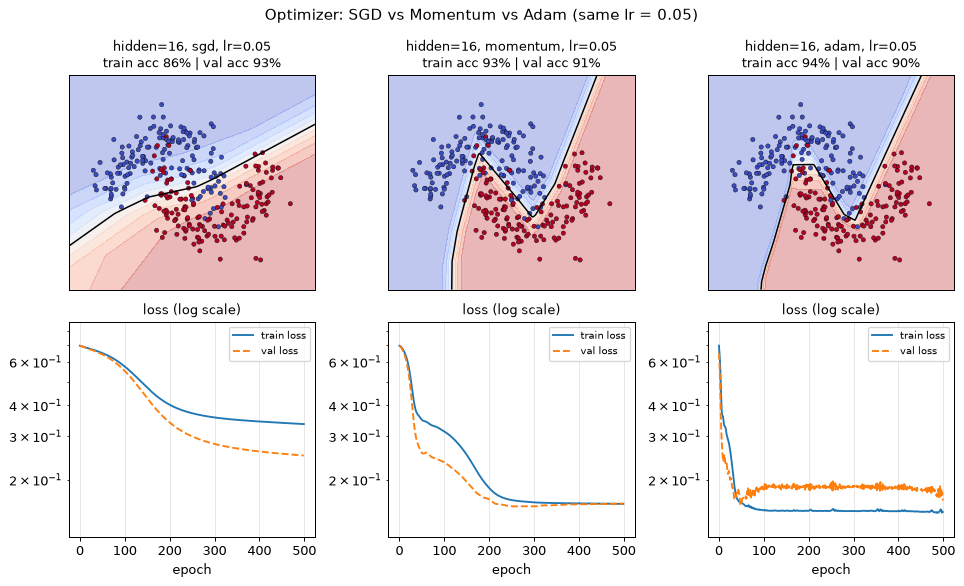

In [12]:
r_opt = [train(moons, hidden=16, optimizer=o, lr=0.05, epochs=500) for o in ["sgd", "momentum", "adam"]]
show(r_opt, "Optimizer: SGD vs Momentum vs Adam (same lr = 0.05)")

> ✅ **확인할 것**: 같은 학습률이어도 **Adam이 가장 빨리** 내려갑니다. Momentum은 '관성'을 써서 SGD보다 빠릅니다.
> 실무에서는 "**일단 Adam, 그리고 학습률 조정**"이 기본값입니다.

### 2-4. ✏️ 직접 해보기
아래 숫자를 바꾸고 **이 셀만 다시 실행**(`Shift + Enter`)해 보세요.

**생각해볼 질문**
1. `HIDDEN = 0`이면 경계는 어떤 모양인가요? 정확도는 몇 %인가요?
2. `OPTIMIZER = "adam"`에서 `LR = 20`이면 어떻게 되나요?
3. `DATA = moons_small`, `HIDDEN = 512`에서 `EPOCHS`를 100으로 줄이면 과적합이 줄어드나요? (조기 종료, early stopping)
4. 과적합된 모델에 `WEIGHT_DECAY`를 0.001, 0.01, 0.1로 바꿔 보세요. 너무 크면 어떻게 되나요?

hidden=64, adam, lr=0.05               | loss train 0.078 / val 0.390 | acc train 95.0% / val 91.0%


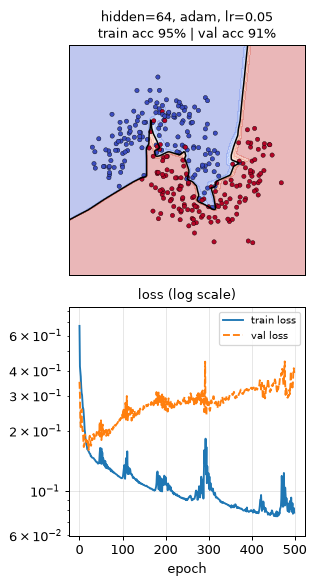

In [13]:
# ✏️ 숫자를 바꿔 보세요
HIDDEN       = 64       # 은닉 뉴런 수: 0(=로지스틱 회귀), 2, 16, 64, 512 ...
LR           = 0.05     # 학습률: 0.001 ~ 20
OPTIMIZER    = "adam"   # "sgd", "momentum", "adam"
EPOCHS       = 500      # 반복 횟수
WEIGHT_DECAY = 0.0      # 가중치 벌점: 0, 0.001, 0.01, 0.1
DATA         = moons    # moons(기본) 또는 moons_small(작고 잡음 큰 데이터)

show([train(DATA, hidden=HIDDEN, lr=LR, optimizer=OPTIMIZER, epochs=EPOCHS, weight_decay=WEIGHT_DECAY)])

---
## 3단계. 통계 데이터로 비교: 로지스틱 회귀 vs 신경망 (10분)
**데이터:** UCI **Adult** (1994년 미국 인구센서스 데이터베이스에서 추출, 48,842명)
**과제:** 연소득이 5만 달러를 넘는지(`>50K`) 예측하기

전형적인 **정형(표) 데이터**입니다. 통계청 마이크로데이터로 바꿔 끼워도 같은 코드가 돌아갑니다.

### 3-1. 🟦 데이터 불러오기

In [14]:
#@title 데이터 불러오기 (CSV 주소 → OpenML → UCI 원본 순서로 시도)
DATA_CSV_URL = None   # 교육장에서 외부 사이트가 막히면, 미리 올려 둔 CSV 주소를 넣으세요 (예: GitHub raw 주소)

ADULT_COLS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
              "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
              "hours-per-week", "native-country", "class"]

def load_adult():
    if DATA_CSV_URL:
        return pd.read_csv(DATA_CSV_URL), "CSV"
    try:
        from sklearn.datasets import fetch_openml
        return fetch_openml("adult", version=2, as_frame=True).frame, "OpenML"
    except Exception:
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
        return pd.read_csv(url, header=None, names=ADULT_COLS, skipinitialspace=True, na_values="?"), "UCI"

adult, source = load_adult()
adult["class"] = adult["class"].astype(str).str.strip().str.rstrip(".")
print(f"출처: {source} | {adult.shape[0]:,}명 × {adult.shape[1]}개 변수")
adult.head()

출처: OpenML | 48,842명 × 15개 변수


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


| 변수 | 뜻 | 비고 |
|---|---|---|
| `age` | 나이 | |
| `workclass` | 고용 형태 (민간, 자영업, 공무원 등) | |
| `fnlwgt` | **표본 가중치** (final weight) | 예측 변수로는 쓰지 않음 |
| `education` / `education-num` | 최종 학력 / 교육 연수 | 같은 정보라 `education-num`만 사용 |
| `marital-status` | 혼인 상태 | |
| `occupation` | 직업 | |
| `relationship` | 가구 내 관계 (남편, 아내, 자녀 등) | |
| `race`, `sex` | 인종, 성별 | 공정성 관점에서 사용 여부 논의 필요 |
| `capital-gain` / `capital-loss` | 자본 이득 / 손실 | 대부분 0, 심하게 치우침 → 로그 변환 |
| `hours-per-week` | 주당 근로시간 | |
| `native-country` | 출생 국가 | |
| `class` | 연소득 5만 달러 초과 여부 | 🎯 맞힐 값 $y$ |

In [15]:
print(adult["class"].value_counts(normalize=True).round(3).to_string())
print("\n→ 모두 '<=50K'라고 찍어도 정확도가 약 76%입니다. 그래서 정확도와 함께 AUC도 봅니다.")

class
<=50K    0.761
>50K     0.239

→ 모두 '<=50K'라고 찍어도 정확도가 약 76%입니다. 그래서 정확도와 함께 AUC도 봅니다.


### 3-2. 전처리: 통계에서 하던 그대로
- 범주형 변수 → **더미변수(원-핫 인코딩)**. 100명 미만인 희소 범주(작은 출생국 등)는 '기타(infrequent)'로 묶어 추정이 불안정해지지 않게 합니다.
- 연속형 변수 → **표준화** (평균 0, 표준편차 1). 신경망은 변수 척도가 다르면 학습이 잘 안 됩니다.
- 치우친 변수(`capital-gain`, `capital-loss`) → **로그 변환**
- **층화추출**로 학습용 80% / 평가용 20% 분할

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
cat_cols = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]

df = adult.copy()
for c in cat_cols:
    df[c] = df[c].astype("object").fillna("Unknown")      # 결측은 'Unknown' 범주로
for c in ["capital-gain", "capital-loss"]:
    df[c] = np.log1p(df[c].astype(float))                 # 치우친 변수 → log(1+x)
y_adult = (df["class"] == ">50K").astype(int).values

X_train_df, X_test_df, y_train, y_test = train_test_split(
    df[num_cols + cat_cols], y_adult, test_size=0.2, random_state=SEED, stratify=y_adult)

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), cat_cols),
])
X_train = prep.fit_transform(X_train_df).astype("float32")
X_test = prep.transform(X_test_df).astype("float32")
feature_names = [n.split("__", 1)[1].replace("infrequent_sklearn", "기타(희소 범주)") for n in prep.get_feature_names_out()]
print(f"학습용 {X_train.shape[0]:,}명 / 평가용 {X_test.shape[0]:,}명 | 특징 {X_train.shape[1]}개 (더미 포함)")

학습용 39,073명 / 평가용 9,769명 | 특징 60개 (더미 포함)


### 3-3. 로지스틱 회귀

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

scores = {}
def record(name, p_test, seconds, interpret):
    scores[name] = {"정확도": accuracy_score(y_test, p_test > 0.5), "AUC": roc_auc_score(y_test, p_test),
                    "학습 시간(초)": seconds, "해석": interpret}
    print(f"{name}: 정확도 {scores[name]['정확도']:.3f} | AUC {scores[name]['AUC']:.3f} | {seconds:.1f}초")

t = time.time()
logreg = LogisticRegression(max_iter=2000).fit(X_train, y_train)
record("로지스틱 회귀", logreg.predict_proba(X_test)[:, 1], time.time() - t, "쉬움 (계수 · 오즈비)")

로지스틱 회귀: 정확도 0.848 | AUC 0.899 | 0.0초


로지스틱 회귀의 장점은 **해석**입니다. 오즈비가 큰 변수와 작은 변수를 봅니다.
(연속형 변수는 표준화했으므로 '1 표준편차 증가당' 오즈비입니다. 여기서는 모든 범주를 더미로 넣고 sklearn 기본값인 약한 L2 벌점을 썼기 때문에, 기준범주 대비 해석과는 조금 다릅니다. 통계 보고용 분석이라면 기준범주를 두고 `statsmodels`로 추정하세요.)

In [18]:
odds = pd.Series(np.exp(logreg.coef_[0]), index=feature_names)
pd.concat([odds.nlargest(6), odds.nsmallest(6)]).round(2).to_frame("오즈비")

,오즈비
marital-status_Married-civ-spouse,4.52
marital-status_기타(희소 범주),2.57
relationship_Wife,2.18
occupation_Exec-managerial,2.14
education-num,2.08
native-country_Canada,1.86
marital-status_Never-married,0.33
occupation_Priv-house-serv,0.33
sex_Female,0.37
relationship_Own-child,0.39


### 3-4. 신경망 (MLP)
1단계와 **같은 학습 루프**입니다. 달라진 점은 하나뿐입니다. 데이터가 3만 명이 넘으므로 한 번에 다 쓰지 않고 **256명씩 뽑은 미니배치**로 기울기를 계산합니다.
→ 통계로 말하면 **표본으로 전체 기울기를 추정**하는 것이고, 이것이 SGD의 'Stochastic(확률적)'입니다.

epoch  1 | train loss 0.3947 | val loss 0.3346
epoch  2 | train loss 0.3217 | val loss 0.3290
epoch  3 | train loss 0.3178 | val loss 0.3272
epoch  4 | train loss 0.3159 | val loss 0.3282
epoch  5 | train loss 0.3142 | val loss 0.3263
epoch  6 | train loss 0.3130 | val loss 0.3277
epoch  7 | train loss 0.3122 | val loss 0.3270
epoch  8 | train loss 0.3116 | val loss 0.3276
epoch  9 | train loss 0.3100 | val loss 0.3277
epoch 10 | train loss 0.3094 | val loss 0.3267
epoch 11 | train loss 0.3087 | val loss 0.3276
epoch 12 | train loss 0.3081 | val loss 0.3277
epoch 13 | train loss 0.3068 | val loss 0.3349
epoch 14 | train loss 0.3068 | val loss 0.3312
epoch 15 | train loss 0.3058 | val loss 0.3302
신경망 (MLP): 정확도 0.850 | AUC 0.907 | 1.1초


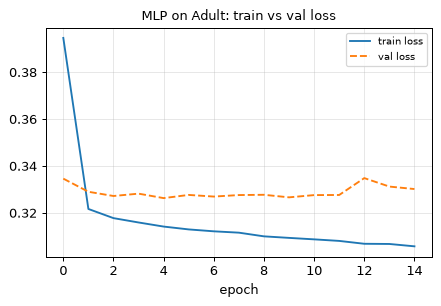

In [19]:
from torch.utils.data import TensorDataset, DataLoader

def fit_mlp(X, y, X_val, y_val, hidden=64, epochs=15, lr=1e-3, batch_size=256, weight_decay=0.0, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    # 🟦 Data: 미니배치로 나눠서 공급
    loader = DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.float32)),
                        batch_size=batch_size, shuffle=True)
    Xv, yv = torch.tensor(X_val), torch.tensor(y_val, dtype=torch.float32)
    # 🟩 Model: 입력 → 64 → 64 → 1
    model = nn.Sequential(nn.Linear(X.shape[1], hidden), nn.ReLU(),
                          nn.Linear(hidden, hidden), nn.ReLU(),
                          nn.Linear(hidden, 1))
    # 🟧 Loss
    loss_fn = nn.BCEWithLogitsLoss()
    # 🟥 Optimizer
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    hist = {"train": [], "val": []}
    for epoch in range(epochs):
        total = 0.0
        for xb, yb in loader:                 # 256명씩 뽑아서
            optimizer.zero_grad()
            loss = loss_fn(model(xb).squeeze(1), yb)
            loss.backward()                   # 기울기 추정
            optimizer.step()                  # 한 걸음
            total += loss.item() * len(xb)
        with torch.no_grad():
            val_loss = loss_fn(model(Xv).squeeze(1), yv).item()
        hist["train"].append(total / len(loader.dataset)); hist["val"].append(val_loss)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {hist['train'][-1]:.4f} | val loss {val_loss:.4f}")
    return model, hist

def predict_proba(model, X):
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(X)).squeeze(1)).numpy()

# 학습용의 10%를 다시 떼어 검증용(val)으로: 학습 중 과적합 감시용
X_tr2, X_val, y_tr2, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=SEED, stratify=y_train)

t = time.time()
mlp, mlp_hist = fit_mlp(X_tr2, y_tr2, X_val, y_val, epochs=15)
record("신경망 (MLP)", predict_proba(mlp, X_test), time.time() - t, "어려움")

fig, ax = plt.subplots(figsize=(5, 3.5))
plot_loss(ax, mlp_hist, title="MLP on Adult: train vs val loss", log=False)
plt.tight_layout(); plt.show()

### 3-5. (참고) 트리 기반 부스팅
정형 데이터에서 자주 가장 좋은 성능을 내는 **그래디언트 부스팅**도 같이 비교해 봅니다. 딥러닝이 아닌 머신러닝 방법입니다.

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier

t = time.time()
hgb = HistGradientBoostingClassifier(random_state=SEED).fit(X_train, y_train)
record("그래디언트 부스팅", hgb.predict_proba(X_test)[:, 1], time.time() - t, "중간 (변수 중요도)")

pd.DataFrame(scores).T.style.format({"정확도": "{:.3f}", "AUC": "{:.3f}", "학습 시간(초)": "{:.1f}"})

그래디언트 부스팅: 정확도 0.873 | AUC 0.928 | 0.9초


,정확도,AUC,학습 시간(초),해석
로지스틱 회귀,0.848,0.899,0.0,쉬움 (계수 · 오즈비)
신경망 (MLP),0.850,0.907,1.1,어려움
그래디언트 부스팅,0.873,0.928,0.9,중간 (변수 중요도)


### 3-6. 표본이 작으면?
학습용 표본을 **300명, 3,000명**만 뽑아서 다시 비교합니다. 평가는 같은 평가용 데이터(9,769명)로 합니다.

,로지스틱 AUC (평가용),MLP AUC (평가용),MLP AUC (학습용)
학습 표본,,,
300명,0.878,0.866,1.000
"3,000명",0.895,0.894,0.953
"35,165명 (전체)",0.899,0.907,0.917


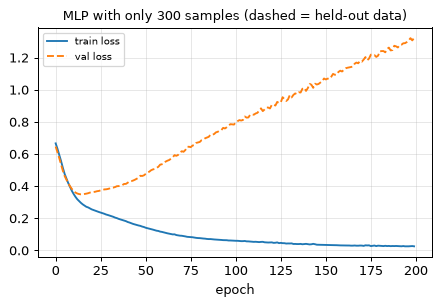

In [21]:
rows, small_hist = [], None
for n, epochs in [(300, 200), (3000, 20)]:
    idx, _ = train_test_split(np.arange(len(y_train)), train_size=n, random_state=SEED, stratify=y_train)
    Xs, ys = X_train[idx], y_train[idx]
    lr_s = LogisticRegression(max_iter=2000).fit(Xs, ys)
    mlp_s, hist_s = fit_mlp(Xs, ys, X_test, y_test, epochs=epochs, batch_size=64, verbose=False)
    if n == 300:
        small_hist = hist_s
    rows.append({"학습 표본": f"{n:,}명",
                 "로지스틱 AUC (평가용)": roc_auc_score(y_test, lr_s.predict_proba(X_test)[:, 1]),
                 "MLP AUC (평가용)": roc_auc_score(y_test, predict_proba(mlp_s, X_test)),
                 "MLP AUC (학습용)": roc_auc_score(ys, predict_proba(mlp_s, Xs))})
rows.append({"학습 표본": f"{len(y_tr2):,}명 (전체)",
             "로지스틱 AUC (평가용)": scores["로지스틱 회귀"]["AUC"],
             "MLP AUC (평가용)": scores["신경망 (MLP)"]["AUC"],
             "MLP AUC (학습용)": roc_auc_score(y_tr2, predict_proba(mlp, X_tr2))})
display(pd.DataFrame(rows).set_index("학습 표본").round(3))

fig, ax = plt.subplots(figsize=(5, 3.5))
plot_loss(ax, small_hist, title="MLP with only 300 samples (dashed = held-out data)", log=False)
plt.tight_layout(); plt.show()

> 💬 **토론**
> - 정형 데이터에서는 신경망이 로지스틱 회귀보다 **크게 낫지 않습니다.** 전체 데이터에서는 AUC가 조금(0.01 안팎) 높을 뿐이고, 가장 좋은 것은 딥러닝이 아닌 **부스팅**입니다.
> - 표본이 300명이면 신경망은 학습용 데이터를 거의 외워 버리고(학습용 AUC ≈ 1.0), 평가용 성능은 **로지스틱 회귀보다 낮아집니다.** 위 그림에서 점선(평가용 loss)이 계속 올라가는 것이 과적합입니다.
> - 로지스틱 회귀는 계수, 오즈비, 표준오차로 **설명**할 수 있습니다. 공식 통계에서는 이것이 큰 장점입니다.
> - 그래서 **정형 데이터 → 기존 통계 기법 / 머신러닝**, **비정형 데이터(텍스트·이미지) → 딥러닝**이 출발점입니다. (7교시 '국가통계를 위한 AI 활용'에서 이어집니다.)
> - 그렇다면 딥러닝은 어디서 강할까요? → 4단계: **텍스트**

---
## 4단계. 사전학습 모델 써보기: 사업체 설명 → 산업분류 (10분)
조사표의 '**주요 사업 내용**' 같은 자유 응답을 **한국표준산업분류**에 배정하는 일을 작게 흉내 내 봅니다.

사용할 모델: **`jhgan/ko-sroberta-multitask`**. 한국어 문장을 숫자 벡터로 바꿔 주는 **RoBERTa 계열 사전학습 모델**입니다.
대량의 한국어 문장으로 **이미 학습된 모델을 내려받아 그대로** 씁니다. 이 모델 자체는 다시 학습하지 않습니다.

### 4-0. 모델 불러오기

In [22]:
#@title 사전학습 모델 불러오기 (처음 한 번 약 440MB 다운로드, 1~2분)
import subprocess, sys
try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"], check=True)
    from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("jhgan/ko-sroberta-multitask", device="cpu")

def embed(texts):
    """문장 목록 → 문장마다 숫자 768개 (길이 1로 정규화)"""
    return embedder.encode(list(texts), normalize_embeddings=True, show_progress_bar=False)

print("모델 준비 완료")

모델 준비 완료


### 4-1. 문장을 숫자로: 비슷한 문장은 비슷한 숫자
1교시에서 본 '**특징(feature)을 사람이 아니라 기계가 만든다**'가 바로 이것입니다.
문장 하나가 숫자 768개짜리 벡터가 되고, **뜻이 비슷한 문장일수록 벡터의 방향이 비슷합니다**(코사인 유사도 ↑).

In [23]:
sents = {
    "치킨집":     "프랜차이즈 치킨 가게를 운영하고 있어요",
    "한식당":     "동네에서 백반과 찌개를 파는 식당을 합니다",
    "앱 개발":    "모바일 애플리케이션을 개발해서 서비스합니다",
    "회계 SW":    "기업용 회계 프로그램을 만들어 판매합니다",
    "자동차 부품": "자동차 부품을 금형으로 찍어서 생산합니다",
}
E = embed(sents.values())
print("문장 1개 → 숫자", E.shape[1], "개:", E[0][:6].round(3), "...")
sim = pd.DataFrame(E @ E.T, index=sents.keys(), columns=sents.keys())
sim.style.background_gradient(cmap="Blues", vmin=0, vmax=1).format("{:.2f}")

문장 1개 → 숫자 768 개: [-0.064  0.046 -0.047 -0.038  0.034 -0.014] ...


,치킨집,한식당,앱 개발,회계 SW,자동차 부품
치킨집,1.00,0.40,0.23,0.26,0.17
한식당,0.40,1.00,0.17,0.17,0.04
앱 개발,0.23,0.17,1.00,0.43,0.33
회계 SW,0.26,0.17,0.43,1.00,0.26
자동차 부품,0.17,0.04,0.33,0.26,1.00


> ✅ '치킨집'과 '한식당'이 서로 가깝고, '앱 개발'과 '회계 SW'가 서로 가깝습니다. **겹치는 단어가 거의 없는데도** 뜻으로 묶입니다.

### 4-2. 🟦 데이터: 사업체 설명 80문장
한국표준산업분류 **대분류 8개**에 대해 분류마다 10문장씩 만든 연습용 데이터입니다. (실제 조사 응답이 아니라 실습용으로 만든 예시입니다.)

In [24]:
KSIC = {"C": "제조업", "F": "건설업", "G": "도매 및 소매업", "H": "운수 및 창고업",
        "I": "숙박 및 음식점업", "J": "정보통신업", "P": "교육 서비스업", "Q": "보건업 및 사회복지 서비스업"}

BIZ = {
    "C": ["자동차용 플라스틱 내장 부품을 사출 성형해 완성차 업체에 납품",
          "공장에서 김치를 대량 생산해 유통업체에 공급",
          "반도체 웨이퍼 세정 장비를 설계하고 제작",
          "원단을 재단하고 봉제해 여성 의류를 생산",
          "철판을 가공해 산업용 기계 부품을 만듦",
          "화장품 원료를 배합해 스킨케어 제품을 제조",
          "목재를 가공해 가정용 가구를 제작",
          "의약품 정제와 캡슐을 생산하는 제약 공장 운영",
          "사료 원료를 배합해 가축용 배합사료를 생산",
          "리튬이온 배터리 셀을 조립하고 생산"],
    "F": ["아파트 신축 공사의 골조 공사를 도급받아 시공",
          "도로 포장 및 보수 공사 수행",
          "상가와 주택의 실내 인테리어 공사, 도배, 바닥 시공",
          "건물 전기 배선과 조명 설비 공사",
          "상하수도 관로 매설 공사",
          "단독주택 리모델링 공사를 전문으로 시공",
          "교량과 터널 등 토목 공사 시공",
          "건물 냉난방 배관 설비 공사",
          "공장 건물의 철골 구조물 설치 공사",
          "노후 건물 철거 및 해체 공사"],
    "G": ["동네에서 편의점을 운영하며 식료품과 생활용품 판매",
          "온라인 쇼핑몰에서 여성 의류를 판매",
          "수입 와인을 들여와 식당과 주류 판매점에 공급",
          "중고 자동차를 매입해 판매",
          "휴대폰과 액세서리를 판매하는 매장 운영",
          "가전제품 전문 매장에서 TV와 냉장고 판매",
          "농산물 도매시장에서 과일을 경매받아 소매상에 납품",
          "철물과 공구를 건설 현장과 철물점에 도매로 공급",
          "꽃집을 운영하며 꽃다발과 화분 판매",
          "사무용품과 문구류를 기업에 납품하는 도매업"],
    "H": ["화물 트럭으로 기업 물품을 전국에 운송",
          "시내버스 노선 운행",
          "택배 물품을 집하해 가정으로 배송",
          "냉동 창고를 운영하며 식품을 보관",
          "개인택시로 승객 운송",
          "컨테이너 화물을 선박으로 해상 운송",
          "국제 항공 화물 운송을 주선하는 포워딩 업무",
          "이삿짐 포장과 운송 서비스",
          "고속버스 터미널 운영",
          "오토바이 퀵서비스로 서류와 소화물 배달"],
    "I": ["프랜차이즈 치킨 전문점 운영",
          "해변 근처에서 펜션 운영",
          "동네에서 한식 백반집 운영",
          "커피 전문점 운영",
          "비즈니스 호텔 운영",
          "회사 구내식당을 위탁받아 단체 급식 제공",
          "저녁에 맥주와 안주를 파는 호프집 운영",
          "피자를 만들어 배달 판매하는 피자 전문점",
          "외국인 관광객 대상 게스트하우스 운영",
          "분식집에서 김밥과 떡볶이 판매"],
    "J": ["스마트폰 앱과 웹 서비스 개발",
          "기업용 회계 소프트웨어 개발 및 판매",
          "모바일 게임 개발 및 서비스",
          "인터넷 포털 사이트 운영",
          "데이터센터에서 서버 호스팅 서비스 제공",
          "지역 신문 발행",
          "드라마와 예능 방송 프로그램 제작",
          "인터넷 회선과 이동통신 서비스 제공",
          "기업 전산 시스템 구축 및 유지보수",
          "라디오 방송국 운영"],
    "P": ["초등학생 대상 수학 학원 운영",
          "사립 초등학교 운영",
          "성인 대상 영어 회화 학원",
          "피아노 교습소 운영",
          "태권도장 운영",
          "자동차 운전 학원 운영",
          "4년제 대학교 운영",
          "코딩 교육 부트캠프 운영",
          "온라인으로 공무원 시험 강의 제공",
          "유치원 운영"],
    "Q": ["내과 의원 운영",
          "치과 의원 진료",
          "요양병원 운영",
          "노인 요양 시설 운영",
          "한의원 운영",
          "장애인 주간보호센터 운영",
          "종합병원 응급실과 입원 진료",
          "어르신 댁을 방문하는 방문 요양 서비스",
          "물리치료 재활 클리닉 운영",
          "건강검진 센터 운영"],
}
biz = pd.DataFrame([(c, t) for c, texts in BIZ.items() for t in texts], columns=["code", "text"])
biz["분류명"] = biz["code"].map(KSIC)

# 분류마다 6문장은 학습용, 4문장은 평가용 (층화)
tr_df, te_df = train_test_split(biz, test_size=0.4, random_state=SEED, stratify=biz["code"])
print(f"전체 {len(biz)}문장 | 학습용 {len(tr_df)} | 평가용 {len(te_df)}")
biz.sample(6, random_state=SEED)

전체 80문장 | 학습용 48 | 평가용 32


,code,text,분류명
50,J,스마트폰 앱과 웹 서비스 개발,정보통신업
27,G,철물과 공구를 건설 현장과 철물점에 도매로 공급,도매 및 소매업
30,H,화물 트럭으로 기업 물품을 전국에 운송,운수 및 창고업
77,Q,어르신 댁을 방문하는 방문 요양 서비스,보건업 및 사회복지 서비스업
45,I,회사 구내식당을 위탁받아 단체 급식 제공,숙박 및 음식점업
71,Q,치과 의원 진료,보건업 및 사회복지 서비스업


### 4-3. 학습 없이 분류하기 (zero-shot)
분류명 자체('제조업', '건설업', …)도 문장처럼 벡터로 바꾼 뒤, **각 사업체 설명과 가장 가까운 분류명**을 고릅니다. 학습 데이터를 하나도 쓰지 않습니다.

In [25]:
codes = list(KSIC)
E_label = embed([KSIC[c] for c in codes])
E_tr, E_te = embed(tr_df["text"]), embed(te_df["text"])

zs_pred = np.array(codes)[(E_te @ E_label.T).argmax(1)]
zs_acc = (zs_pred == te_df["code"].values).mean()
print(f"zero-shot 정확도: {zs_acc:.1%}  (8개 중 무작위로 찍으면 12.5%)")

view = te_df[["text", "code"]].assign(예측=zs_pred).rename(columns={"text": "사업 내용", "code": "정답"})
view[view["정답"] != view["예측"]].head(8)   # 틀린 것만 보기

zero-shot 정확도: 93.8%  (8개 중 무작위로 찍으면 12.5%)


,사업 내용,정답,예측
64,태권도장 운영,P,I
3,원단을 재단하고 봉제해 여성 의류를 생산,C,G


### 4-4. 조금만 학습하기 (few-shot): 임베딩 위에 로지스틱 회귀
분류마다 **6문장**(총 48문장)만 보여 주고 학습합니다.
- 🟦 Data: 사전학습 모델이 만든 768개 특징
- 🟩 Model: **다항 로지스틱 회귀** (우리에게 익숙한 그 모델!)
- 🟧 Loss: 교차엔트로피 (= 다항 로지스틱의 음의 로그우도)
- 🟥 Optimizer: L-BFGS (sklearn 기본값)

비교를 위해, 사전학습 모델 없이 **글자 조각 빈도**(TF-IDF)를 특징으로 쓴 로지스틱 회귀도 같이 돌립니다. 모델은 같고 **특징만** 다릅니다.

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer

# (a) 사전학습 임베딩 + 로지스틱 회귀
clf = LogisticRegression(max_iter=5000, C=10).fit(E_tr, tr_df["code"])
fs_pred = clf.predict(E_te)
fs_acc = (fs_pred == te_df["code"].values).mean()

# (b) 글자 2~3그램 빈도(TF-IDF) + 로지스틱 회귀  ← 사람이 정한 특징
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
clf_tfidf = LogisticRegression(max_iter=5000, C=10).fit(tfidf.fit_transform(tr_df["text"]), tr_df["code"])
tfidf_acc = (clf_tfidf.predict(tfidf.transform(te_df["text"])) == te_df["code"].values).mean()

pd.DataFrame({
    "학습 문장 수": [0, len(tr_df), len(tr_df)],
    "평가 정확도": [zs_acc, tfidf_acc, fs_acc],
}, index=["zero-shot (분류명과 유사도)", "TF-IDF + 로지스틱 회귀", "사전학습 임베딩 + 로지스틱 회귀"]).style.format({"평가 정확도": "{:.1%}"})

,학습 문장 수,평가 정확도
zero-shot (분류명과 유사도),0,93.8%
TF-IDF + 로지스틱 회귀,48,62.5%
사전학습 임베딩 + 로지스틱 회귀,48,93.8%


> ✅ **확인할 것**
> - **같은 로지스틱 회귀**인데 특징만 바꿨더니 정확도가 크게 다릅니다. 글자 빈도(사람이 정한 특징)는 60%대, 사전학습 임베딩(기계가 학습한 특징)은 90%대입니다. 48문장밖에 없어도 사전학습 모델이 '뜻'을 이미 알고 있기 때문입니다.
> - 이 연습용 문장은 짧고 전형적이라 **학습 없이(zero-shot)도** 잘 맞힙니다. 실제 조사 응답은 훨씬 지저분하고 분류도 세분화되어 있어서, 학습 데이터가 있어야 성능이 나옵니다.

In [27]:
# 혼동행렬: 행 = 정답, 열 = 예측
pd.crosstab(te_df["code"].values, fs_pred, rownames=["정답"], colnames=["예측"])

예측,C,F,G,H,I,J,P,Q
정답,,,,,,,,
C,4,0,0,0,0,0,0,0
F,0,4,0,0,0,0,0,0
G,1,0,3,0,0,0,0,0
H,1,0,0,3,0,0,0,0
I,0,0,0,0,4,0,0,0
J,0,0,0,0,0,4,0,0
P,0,0,0,0,0,0,4,0
Q,0,0,0,0,0,0,0,4


### 4-5. ✏️ 직접 입력해 보기
사업 내용을 입력하면 **상위 3개 분류와 확률**을 보여 줍니다. Colab에서는 오른쪽 입력칸에 바로 쓸 수 있습니다.

In [28]:
def classify(text, k=3):
    p = clf.predict_proba(embed([text]))[0]
    top = np.argsort(p)[::-1][:k]
    return pd.DataFrame({"분류": [f"{clf.classes_[i]} {KSIC[clf.classes_[i]]}" for i in top],
                         "확률": [f"{p[i]:.1%}" for i in top]}, index=range(1, k + 1))

text = "아이들에게 그림 그리기를 가르치는 미술 학원을 운영합니다"  #@param {type:"string"}
classify(text)

,분류,확률
1,P 교육 서비스업,74.2%
2,G 도매 및 소매업,5.2%
3,F 건설업,3.9%


### 🤔 생각해볼 문제
아래 세 사업체는 어느 대분류일까요? **먼저 직접 맞혀 보고**, 모델의 답을 본 다음, 정답을 열어 보세요.

In [29]:
puzzles = ["약국을 운영하며 처방약과 일반의약품을 판매합니다",
           "어린이집을 운영하며 영유아를 보육합니다",
           "직접 구운 빵과 케이크를 매장에서 파는 동네 제과점입니다"]
for s in puzzles:
    top = classify(s, k=1).iloc[0]
    print(f"{s}\n   → 모델: {top['분류']} ({top['확률']})\n")

약국을 운영하며 처방약과 일반의약품을 판매합니다
   → 모델: G 도매 및 소매업 (33.3%)

어린이집을 운영하며 영유아를 보육합니다
   → 모델: P 교육 서비스업 (33.4%)

직접 구운 빵과 케이크를 매장에서 파는 동네 제과점입니다
   → 모델: G 도매 및 소매업 (33.5%)



<details>
<summary><b>정답 보기 (한국표준산업분류 기준)</b></summary>

- **약국** → **G 도매 및 소매업** (의약품 소매업). 보건(Q)이 아닙니다.
- **어린이집** → **Q 보건업 및 사회복지 서비스업** (보육시설 운영). 교육(P)이 아닙니다. 유치원은 P입니다.
- **제과점** → **I 숙박 및 음식점업** (제과점업). 빵을 만들지만 제조업(C)이 아닙니다.

모델은 '**뜻이 비슷한가**'는 잘 보지만, 분류 지침의 **예외 규칙**은 모릅니다. 위 결과에서도 1순위 확률이 낮게 나왔고, 맞힌 경우도 자신 없이 맞힌 것입니다.
이런 사례는 학습 데이터에 충분히 넣어 주고, 확률이 낮은 건은 사람이 검토해야 합니다.
</details>

### 4-6. 국가통계와의 연결
7교시에서 소개할 통계청의 **AI 기반 통계분류 자동화 시스템**도 같은 구조입니다. 2023년 시스템은 **RoBERTa** 계열 사전학습 모델을 활용합니다.

| 오늘 실습 | 실제 시스템 |
|---|---|
| 사전학습 모델(고정) + 로지스틱 회귀 | 사전학습 모델 전체를 미세조정(fine-tuning) |
| 48문장, 대분류 8개 | 훨씬 많은 실제 조사 응답, 세세분류까지 |

**주의할 점**
- **예외 규칙**(약국, 어린이집, 제과점 같은 사례)은 데이터와 분류 지침으로 보완해야 합니다.
- **확률이 낮은 건은 사람이 검토**하도록 설계합니다. 자동 분류 + 사람 검토(human-in-the-loop).
- 새 업종이 생기거나 분류 개정이 있으면 **다시 학습**해야 합니다.

---
## 마무리: 오늘 만난 4요소

| 요소 | 1·2단계 (점 데이터) | 3단계 (인구센서스) | 4단계 (산업분류) |
|---|---|---|---|
| 🟦 **Data** | 점 400개, 설명변수 2개 | 3만여 명, 더미 포함 특징 60개 | 사업체 설명 48문장 |
| 🟩 **Model** | 은닉층 2개 MLP (0개면 로지스틱 회귀) | 로지스틱 회귀 / MLP / 부스팅 | 사전학습 RoBERTa(고정) + 로지스틱 회귀 |
| 🟧 **Loss** | 이진 교차엔트로피 (+ Ridge 벌점) | 이진 교차엔트로피 | 다항 교차엔트로피 |
| 🟥 **Optimizer** | SGD / Momentum / Adam | Adam (미니배치) | L-BFGS |

### 오늘의 핵심
1. 딥러닝의 **Loss는 우도**, **Optimizer는 추정 알고리즘**입니다. 은닉층 없는 신경망은 로지스틱 회귀입니다.
2. **학습률**과 **과적합 관리**(검증용 데이터, 벌점)가 실무에서 가장 중요합니다.
3. **정형 데이터는 통계·머신러닝**, **텍스트·이미지는 사전학습 딥러닝 모델**이 출발점입니다.

In [30]:
print(f"전체 실행 시간: {time.time() - t_start:.0f}초")

전체 실행 시간: 16초
